# Underwriting Model and Credit Policy Simulator
The transaction data has no application or credit bureau data and no default outcomes, so this notebook works with a **simulated** applicant population whose true default process is known. That lets us:
1. build an underwriting model on the applicants that were booked (the only ones with outcomes, like real life), and
2. use the model's score in a credit policy simulator that projects NPV and losses under random economies.

The underwriting score is the model's probability of **not** defaulting in the next 12 months. A credit policy sets an initial credit line and APR for each score band (deciles here) and an approve/decline threshold on the score.

## 0. Setup

In [1]:
# Common imports
import numpy as np
import pandas as pd

import os

# The notebooks live in notebooks/; work from the project root so the config paths resolve.
working_directory = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(working_directory)

# To make this notebook's output stable across runs
np.random.seed(42)

# To see the columns in our DataFrames
pd.options.display.max_columns = 500

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
import seaborn as sns; sns.set()

def save_fig(fig_id, tight_layout=True, fig_extension="png",
             verbose=True, resolution=300):
    path = os.path.join(working_directory, "images", fig_id + "." + fig_extension)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    if verbose:
        print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. The Simulated Applicant Population

In [2]:
from card_risk.config import load_config
from card_risk.underwriting import simulate_applicant_population

config = load_config()

In [3]:
%%time
applications = simulate_applicant_population(config.underwriting)

CPU times: user 1.92 s, sys: 20.2 ms, total: 1.94 s
Wall time: 1.95 s


In [4]:
applications.shape

(200000, 22)

In [5]:
applications.head()

,application_id,latent_creditworthiness,vintage,application_date,fico_score,revolving_utilization,num_credit_inquiries_6m,num_delinquencies_24m,months_since_oldest_tradeline,num_open_tradelines,annual_income,debt_to_income,employment_years,housing_status,application_channel,requested_credit_limit,total_revolving_balance,true_pd_12m,revolving_balance_demand,monthly_spend_demand,is_booked,defaulted_12m
0,24157,0.583321,1,2017-01-01,747,0.405,1,0,152,4,44600.0,0.159,10.0,OWN,DIGITAL,4500.0,2480.0,0.018178,5280.0,520.0,1,0.0
1,152776,-1.012970,1,2017-01-01,658,0.594,3,0,63,4,27400.0,0.326,10.3,MORTGAGE,DIGITAL,2000.0,2970.0,0.129883,8600.0,180.0,1,0.0
2,16776,-0.893304,1,2017-01-01,608,0.502,1,0,145,6,20900.0,0.289,5.7,RENT,DIRECT_MAIL,2500.0,2400.0,0.071550,2530.0,130.0,0,NaN
3,71044,-0.234110,1,2017-01-01,681,0.332,1,0,152,4,39500.0,0.340,16.9,OWN,DIRECT_MAIL,2000.0,4340.0,0.059786,8800.0,210.0,1,0.0
4,127729,-1.307605,1,2017-01-01,610,0.303,3,0,54,1,35100.0,0.401,0.0,OWN,DIGITAL,6000.0,2560.0,0.217523,6090.0,500.0,0,NaN


In [6]:
applications.describe()

,application_id,latent_creditworthiness,vintage,application_date,fico_score,revolving_utilization,num_credit_inquiries_6m,num_delinquencies_24m,months_since_oldest_tradeline,num_open_tradelines,annual_income,debt_to_income,employment_years,requested_credit_limit,total_revolving_balance,true_pd_12m,revolving_balance_demand,monthly_spend_demand,is_booked,defaulted_12m
count,200000.000000,200000.000000,200000.000000,200000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.00000,200000.000000,200000.000000,200000.000000,200000.000000,138229.000000
mean,99999.500000,0.000954,12.500955,2017-12-29 12:09:09.072000,690.071040,0.384754,1.296300,0.273605,151.052755,6.001280,65963.369500,0.300166,5.042029,7823.130000,5673.58735,0.115681,11076.526550,622.750950,0.691145,0.055987
min,0.000000,-4.502222,1.000000,2017-01-01 00:00:00,389.000000,0.003000,0.000000,0.000000,0.000000,0.000000,12000.000000,0.000000,0.000000,500.000000,30.00000,0.000324,230.000000,20.000000,0.000000,0.000000
25%,49999.750000,-0.670915,7.000000,2017-07-01 00:00:00,650.000000,0.196000,0.000000,0.000000,94.000000,4.000000,36500.000000,0.221000,1.500000,4000.000000,2220.00000,0.020529,4520.000000,270.000000,0.000000,0.000000
50%,99999.500000,0.000290,13.000000,2018-01-01 00:00:00,690.000000,0.355000,1.000000,0.000000,150.000000,6.000000,55000.000000,0.300000,3.600000,6000.000000,4130.00000,0.051522,7870.000000,460.000000,1.000000,0.000000
75%,149999.250000,0.674031,19.000000,2018-07-01 00:00:00,731.000000,0.552000,2.000000,0.000000,206.000000,8.000000,82700.000000,0.379000,7.100000,10000.000000,7390.00000,0.132187,13780.000000,780.000000,1.000000,0.000000
max,199999.000000,4.522830,24.000000,2018-12-28 00:00:00,850.000000,0.993000,11.000000,11.000000,529.000000,24.000000,750000.000000,0.895000,45.000000,30000.000000,120920.00000,0.999729,283330.000000,17780.000000,1.000000,1.000000
std,57735.171256,0.999076,6.919852,NaN,60.174094,0.226892,1.230859,0.606957,80.490108,2.878783,43602.430621,0.115936,5.033458,5690.373793,5264.33161,0.164205,10795.912913,575.070592,0.462022,0.229897


The historical underwriting rule booked about 69% of applicants, and only booked applicants have an observed default.

In [7]:
applications.groupby("is_booked").agg(
    applicants=("application_id", "size"),
    mean_fico=("fico_score", "mean"),
    true_pd=("true_pd_12m", "mean"),
    observed_default_rate=("defaulted_12m", "mean"),
)

,applicants,mean_fico,true_pd,observed_default_rate
is_booked,,,,
0,61771,632.836606,0.256024,NaN
1,138229,715.647643,0.052966,0.055987


The declined applicants are much riskier (their true PD is about five times higher, 26% vs 5%), but we never see their outcomes. A model trained only on booked accounts has never seen most of the risky end of the population, which is why the underwriting model uses monotone constraints: when it extrapolates to applicants the old rule declined, a lower FICO or higher debt-to-income can only make the score worse. Reject inference would be the next step.

I'm also curious whether defaults drift over time, since the simulation includes a mild economic deterioration in later vintages.

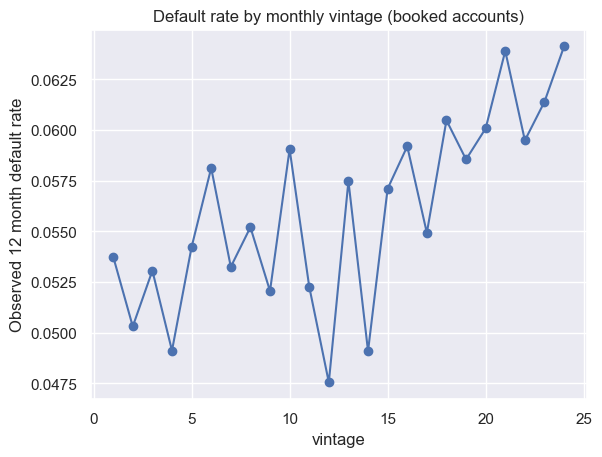

In [8]:
applications[applications["is_booked"] == 1].groupby("vintage")["defaulted_12m"].mean().plot(marker="o")
plt.ylabel("Observed 12 month default rate")
plt.title("Default rate by monthly vintage (booked accounts)")
plt.show()

They drift up, which is exactly why the model is evaluated out of time on the last six vintages.

## 2. Underwriting Model

`underwriting-train` trains on vintages 1-16, early stops on 17-18 and tests on 19-24, all on booked accounts. It compares a monotone-constrained XGBoost with a logistic regression scorecard and with an "oracle" that knows the true PD.

In [9]:
import json

with open(config.paths.reports_dir / "underwriting" / "metrics.json") as f:
    uw_metrics = json.load(f)
pd.DataFrame({name: uw_metrics[name] for name in ["xgboost", "logistic_scorecard", "oracle_true_pd"]}).T[
    ["roc_auc", "gini", "ks", "brier", "mean_predicted", "positive_rate"]]

,roc_auc,gini,ks,brier,mean_predicted,positive_rate
xgboost,0.750249,0.500499,0.369197,0.053284,0.053740,0.061251
logistic_scorecard,0.755621,0.511243,0.374666,0.052984,0.053579,0.061251
oracle_true_pd,0.779657,0.559315,0.417897,0.051905,0.052366,0.061251


Both models are close to the oracle, and the logistic scorecard is as good as XGBoost here. That's because the simulated default process is mostly linear in the log-odds, so this is a case where the simpler, more explainable scorecard would be the right production choice; with real bureau data the non-linearities are usually larger and boosting earns its keep.

In [10]:
pd.read_csv(config.paths.reports_dir / "underwriting" / "score_deciles.csv", index_col=0)

,n,min_score,max_score,mean_predicted,observed_rate,share_of_positives
bin,,,,,,
1,3449,0.004585,0.011410,0.008836,0.006669,0.010890
2,3448,0.011410,0.016356,0.013843,0.014791,0.024148
3,3448,0.016356,0.022188,0.019135,0.023782,0.038826
4,3448,0.022188,0.029944,0.025892,0.030162,0.049242
5,3448,0.029947,0.039024,0.034369,0.037703,0.061553
6,3448,0.039025,0.048924,0.043922,0.047564,0.077652
7,3448,0.048925,0.060806,0.054622,0.061195,0.099905
8,3448,0.060815,0.077179,0.068452,0.074246,0.121212
9,3448,0.077194,0.106788,0.089992,0.109919,0.179451


The score rank orders cleanly on the out-of-time vintages, but it under-predicts in the riskiest deciles (about 18% predicted vs 21% observed in the top decile). That's the vintage drift we saw above: defaults rose after the training window. In production I'd recalibrate on recent vintages; here it is a nice reminder of why the simulator scores outcomes with the true PD rather than trusting the model.

## 3. The Credit Policy Simulator

The simulator books a policy on the out-of-time through-the-door population (about 50,000 applicants, booked or not, scored by the underwriting model) and projects 12 quarters:
- **Economy:** quarter 1 is today's economy; after that a scenario is drawn (boom 15%, benign 50%, minor recession 25%, recession 10%) that moves unemployment, GDP growth, CPI and the Case-Shiller home price index, with noise around each path.
- **Loss model:** quarterly PD = the account's baseline PD x a seasoning curve (losses peak in year two), shifted in log-odds by lagged unemployment, the 4-quarter change in unemployment, the year-over-year growth of the 2-quarter average Case-Shiller index, 2-quarter average GDP growth and lagged CPI. LGD and revolving balances also rise when unemployment does.
- **NPV model:** interest on revolving balances, interchange, fees, rewards, fraud losses net of the fraud model, cost of funds (tied to CPI), servicing, charge-offs and attrition, discounted at 12%, minus acquisition cost.

Policy decisions use the model's score, but outcomes come from the true simulated PD, so model error shows up in the results.

In [11]:
from card_risk.simulator import (
    CreditPolicy,
    ECONOMIC_SCENARIOS,
    simulate_macro_path,
    simulate_policy_across_economic_scenarios,
    simulate_policies_in_fixed_economy,
    sample_random_credit_policies,
)
from card_risk.simulator.run import load_credit_policy_simulator, summarize_npv_by_scenario

simulator = load_credit_policy_simulator(config)
policy = CreditPolicy.from_config(config.simulator)
policy

CreditPolicy(approve_threshold=0.9, credit_lines_by_band=[500, 1000, 1500, 2000, 3000, 4000, 5000, 7000, 9000, 12000], apr_by_band=[0.299, 0.289, 0.279, 0.269, 0.259, 0.249, 0.239, 0.229, 0.219, 0.199])

Here is the score band table with the policy's lines and APRs. Band 1 is the riskiest decile.

In [12]:
bands = simulator.get_band_score_ranges(policy.n_bands)
bands["credit_line"] = policy.credit_lines_by_band
bands["apr"] = policy.apr_by_band
bands["approved"] = bands["max_score"] >= policy.approve_threshold
bands

,min_score,max_score,applicants,true_pd_12m,credit_line,apr,approved
band,,,,,,,
1,0.136235,0.701952,5003,0.505936,500,0.299,False
2,0.701970,0.837075,5004,0.228664,1000,0.289,False
3,0.837080,0.893428,5003,0.138999,1500,0.279,False
4,0.893434,0.922543,5004,0.094803,2000,0.269,True
5,0.922564,0.941703,5004,0.066410,3000,0.259,True
6,0.941711,0.955990,5003,0.047649,4000,0.249,True
7,0.955991,0.968739,5004,0.034170,5000,0.239,True
8,0.968740,0.979090,5003,0.024612,7000,0.229,True
9,0.979094,0.986620,5004,0.015716,9000,0.219,True


Let's look at what the scenarios do to the economy, starting with the expected recession path.

In [13]:
recession_path = simulate_macro_path("recession", config.simulator.n_quarters, with_noise=False)
recession_path[["unemployment_rate", "unemployment_change_4q", "gdp_growth_avg_2q",
                "cpi_inflation", "case_shiller_hpi", "hpi_avg_2q_yoy_growth"]].round(2)

,unemployment_rate,unemployment_change_4q,gdp_growth_avg_2q,cpi_inflation,case_shiller_hpi,hpi_avg_2q_yoy_growth
quarter,,,,,,
1,4.00,0.00,2.20,2.60,339.39,4.00
2,5.92,1.92,0.25,1.80,337.48,3.20
3,7.25,3.25,-2.54,1.29,332.12,1.09
4,8.12,4.12,-3.59,0.99,324.80,-1.79
5,8.65,4.65,-3.67,0.84,316.64,-5.04
6,8.92,3.00,-3.23,0.80,308.40,-7.66
7,9.00,1.75,-2.57,0.83,300.59,-9.05
8,8.94,0.82,-1.85,0.91,293.48,-9.57
9,8.78,0.12,-1.16,1.02,287.19,-9.47


And the policy under each scenario's expected path:

In [14]:
rows = {}
for scenario in ECONOMIC_SCENARIOS:
    rows[scenario] = simulator.evaluate(policy, simulate_macro_path(scenario, config.simulator.n_quarters, with_noise=False))
pd.DataFrame(rows).T[["npv", "npv_per_account", "approval_rate", "net_charge_off_rate",
                      "cumulative_unit_default_rate", "risk_adjusted_margin", "return_on_assets", "breakeven_quarter"]]

,npv,npv_per_account,approval_rate,net_charge_off_rate,cumulative_unit_default_rate,risk_adjusted_margin,return_on_assets,breakeven_quarter
boom,6.421583e+06,188.670315,0.68023,0.028292,0.087160,0.132415,0.056775,7.0
benign,7.104087e+06,208.722745,0.68023,0.032200,0.098649,0.127446,0.058904,6.0
minor_recession,5.943709e+06,174.630062,0.68023,0.040540,0.122164,0.117745,0.054677,7.0
recession,7.237485e+05,21.264204,0.68023,0.064348,0.184997,0.091036,0.036747,12.0


Charge-offs roughly double from benign to recession (about 3% to 6.4% annualized), which is in line with US card losses through past downturns, and the policy still makes money in a recession but breaks even much later. Boom NPV is slightly below benign: higher inflation in a boom raises the cost of funds.

### 3.1 Monte Carlo Way One: Fixed Policy, Random Economies

In [15]:
%%time
df_paths = simulate_policy_across_economic_scenarios(simulator, policy, n_paths=500,
                                                     n_quarters=config.simulator.n_quarters, seed=11)

CPU times: user 7.99 s, sys: 3.11 s, total: 11.1 s
Wall time: 11.1 s


In [16]:
summarize_npv_by_scenario(df_paths)

,paths,npv_mean,npv_p5,npv_p50,npv_p95,prob_npv_negative,net_charge_off_rate_mean,return_on_assets_mean
scenario,,,,,,,,
boom,74.0,6.569569e+06,5.581297e+06,6.487472e+06,7.768513e+06,0.000000,0.028251,0.057260
benign,253.0,7.122221e+06,6.159534e+06,7.112204e+06,8.299540e+06,0.000000,0.032232,0.058986
minor_recession,124.0,5.891465e+06,4.940727e+06,5.948402e+06,6.951991e+06,0.000000,0.040546,0.054527
recession,49.0,8.650358e+05,-7.573595e+04,6.134728e+05,1.970334e+06,0.081633,0.064192,0.037194
all,500.0,6.121997e+06,8.573162e+05,6.543188e+06,7.981486e+06,0.008000,0.036837,0.055489


In [17]:
for scenario in ECONOMIC_SCENARIOS:
    subset = df_paths.loc[df_paths["scenario"] == scenario, "npv"] / 1e6
    plt.hist(subset, bins=30, alpha=0.6, label=scenario)
plt.xlabel("Portfolio NPV ($M)")
plt.ylabel("Economic paths")
plt.title("Fixed policy, random economies")
plt.legend()
plt.show()

Within a scenario, how much does the path matter? Peak unemployment drives much of the spread:

In [18]:
df_paths.plot(kind="scatter", x="peak_unemployment_rate", y="npv", alpha=0.3, figsize=(8, 5))
plt.title("NPV vs peak unemployment")
plt.show()

### 3.2 Monte Carlo Way Two: Fixed Economy, Random Policies

Now fix the economy and ask what all the possible policies would have returned, and where our policy ranks.

In [19]:
policies = sample_random_credit_policies(1000, policy.n_bands, np.random.default_rng(12))

In [20]:
%%time
results = {scenario: simulate_policies_in_fixed_economy(simulator, policies, scenario, config.simulator.n_quarters)
           for scenario in ["benign", "recession"]}

CPU times: user 23.6 s, sys: 10.7 s, total: 34.3 s
Wall time: 34.4 s


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (scenario, df_policies) in zip(axes, results.items()):
    mine = rows[scenario]
    ax.scatter(100 * df_policies["net_charge_off_rate"], df_policies["npv"] / 1e6, s=6, alpha=0.3)
    ax.scatter(100 * mine["net_charge_off_rate"], mine["npv"] / 1e6, s=150, marker="*", color="k", label="our policy")
    ax.set_xlabel("Annualized net charge-off rate (%)")
    ax.set_ylabel("NPV ($M)")
    ax.set_title(f"{scenario}: our policy beats {100 * (df_policies['npv'] < mine['npv']).mean():.0f}% of policies")
    ax.legend()
plt.show()

What do the best policies look like in each economy?

In [22]:
{scenario: df_policies.sort_values("npv", ascending=False).head(3)[
    ["npv", "approve_threshold", "credit_lines_by_band", "approval_rate", "net_charge_off_rate"]]
 for scenario, df_policies in results.items()}

{'benign':               npv  approve_threshold  \
 112  1.889290e+07              0.891   
 668  1.865827e+07              0.863   
 247  1.803029e+07              0.941   
 
                                   credit_lines_by_band  approval_rate  \
 112  [750, 1000, 1500, 4000, 5000, 7500, 10000, 100...       0.705952   
 668  [750, 1000, 1000, 3000, 6000, 6000, 7500, 1000...       0.763830   
 247  [500, 500, 500, 2000, 2000, 3000, 7500, 7500, ...       0.503657   
 
      net_charge_off_rate  
 112             0.042689  
 668             0.040734  
 247             0.027363  ,
 'recession':               npv  approve_threshold  \
 247  1.422631e+07              0.941   
 449  1.193214e+07              0.960   
 273  1.050648e+07              0.965   
 
                                   credit_lines_by_band  approval_rate  \
 247  [500, 500, 500, 2000, 2000, 3000, 7500, 7500, ...       0.503657   
 449  [2000, 2500, 3000, 5000, 6000, 7500, 9000, 900...       0.369934   
 273  [500, 

In a benign economy the best policies approve more and give the top bands much larger lines; in a recession the best policies tighten the threshold and cut lines in the lower bands. Let's try that idea: a recession-ready policy with a tighter threshold and smaller lines at the bottom, and see how it does across *all* economies.

In [23]:
recession_ready = CreditPolicy(
    approve_threshold=0.93,
    credit_lines_by_band=[500, 500, 1000, 1500, 2500, 4000, 6000, 9000, 12000, 15000],
    apr_by_band=policy.apr_by_band,
)
df_paths_recession_ready = simulate_policy_across_economic_scenarios(
    simulator, recession_ready, n_paths=500, n_quarters=config.simulator.n_quarters, seed=11)

In [24]:
pd.concat({"current policy": summarize_npv_by_scenario(df_paths)[["npv_mean", "npv_p5", "prob_npv_negative"]],
           "recession ready": summarize_npv_by_scenario(df_paths_recession_ready)[["npv_mean", "npv_p5", "prob_npv_negative"]]},
          axis=1)

current policy                                  \
                      npv_mean        npv_p5 prob_npv_negative   
scenario                                                         
boom              6.569569e+06  5.581297e+06          0.000000   
benign            7.122221e+06  6.159534e+06          0.000000   
minor_recession   5.891465e+06  4.940727e+06          0.000000   
recession         8.650358e+05 -7.573595e+04          0.081633   
all               6.121997e+06  8.573162e+05          0.008000   

                recession ready                                  
                       npv_mean        npv_p5 prob_npv_negative  
scenario                                                         
boom               8.792761e+06  7.822961e+06               0.0  
benign             9.503817e+06  8.550734e+06               0.0  
minor_recession    8.639933e+06  7.719840e+06               0.0  
recession          4.334322e+06  3.344315e+06               0.0  
all                8.677727e+06  4.307444e+06               0.0

Because the same seed is used, both policies face exactly the same 500 economies, so this is a like-for-like comparison. The recession-ready policy wins in *every* scenario, not just the recession: about $8.7M vs $6.1M expected NPV, and its 5th percentile ($4.3M) is far above the current policy's ($0.9M), with no paths losing money. The default policy's lines are too small for the best bands and too large for the riskiest bands it approves, which is exactly what the random-policy search pointed to. A policy that is robust to a downturn doesn't have to cost anything in good times.

## 4. Summary and Thoughts on Further Work

- The underwriting model's score, P(no default in 12 months), rank orders and is well calibrated out of time, even though it only learns from booked accounts.
- The simulator turns a policy (lines and APRs by score band, plus a threshold) into NPV and a suite of credit metrics, under a random economy drawn after the first quarter.
- Monte Carlo over economies shows the downside of a policy (a recession is what makes NPV negative); Monte Carlo over policies shows how much better a policy could be in a given economy, and which direction to move.

With more time I would:
- estimate the macro sensitivities of the loss model from real vintage data (e.g. public charge-off series against unemployment and home prices) instead of setting them by hand;
- let lines change over time (credit line increases and decreases) and model balance build by vintage;
- add reject inference so the underwriting model learns about applicants the old rule declined;
- optimize the policy directly (e.g. maximize expected NPV subject to a 5th percentile NPV floor) instead of random search.